<a href="https://colab.research.google.com/github/Joao-Barbi/streaming_churn/blob/master/Estat%C3%ADtica_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Montar o Google Drive
Primeiro, precisamos conectar o Google Colab ao seu Google Drive para conseguir acessar a pasta.

In [55]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2. Localizar e Carregar o Arquivo
Vamos procurar pelo arquivo `clientes_base.csv` na pasta `Phyton` e carregá-lo em um DataFrame do pandas.

In [57]:
import os
import pandas as pd

# Caminho base do Drive
caminho_pasta = '/content/drive/My Drive/Phyton'

# Listar arquivos para confirmar o nome e extensão (ex: .csv, .xlsx)
if os.path.exists(caminho_pasta):
    arquivos = os.listdir(caminho_pasta)
    print("Arquivos encontrados na pasta Phyton:", arquivos)

    # Tentar encontrar o arquivo clientes_base
    arquivo_alvo = [f for f in arquivos if 'clientes_base' in f]
    if arquivo_alvo:
        caminho_arquivo = os.path.join(caminho_pasta, arquivo_alvo[0])
        print(f"Carregando arquivo: {caminho_arquivo}")

        # Carrega dependendo da extensão
        if caminho_arquivo.endswith('.csv'):
            df = pd.read_csv(caminho_arquivo)
        elif caminho_arquivo.endswith(('.xls', '.xlsx')):
            df = pd.read_excel(caminho_arquivo)
        else:
            # Tenta ler como CSV por padrão se não tiver extensão mapeada
            df = pd.read_csv(caminho_arquivo)
    else:
        print("Arquivo 'clientes_base' não foi encontrado na pasta 'Phyton'. Verifique o nome.")
else:
    print("A pasta 'Phyton' não foi encontrada no caminho padrão do Drive. Verifique se o nome está correto (ex: 'Python' ou 'Phyton').")

Arquivos encontrados na pasta Phyton: ['clientes_base.csv', 'funil_eventos.csv', 'dados_modelo_antigo.xlsx', 'Modelo fraude.ipynb', 'Estatítica I.ipynb']
Carregando arquivo: /content/drive/My Drive/Phyton/clientes_base.csv


### 3. Exibir o DataFrame e os Tipos das Colunas

In [28]:
if 'df' in locals():
    print("--- Primeiras Linhas do DataFrame ---")
    display(df.head())

    print("\n--- Tipos das Colunas ---")
    display(df.dtypes)
else:
    print("DataFrame não foi carregado. Certifique-se de que o passo anterior rodou com sucesso.")

--- Primeiras Linhas do DataFrame ---


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0



--- Tipos das Colunas ---


,0
cliente_id,int64
idade,int64
plano,object
ciclo,object
valor_mensal,float64
regiao,object
canal_aquisicao,object
nps,int64
data_assinatura,object
data_cancelamento,object


### 4. Análise de Frequência e Gráficos de Barras
Vamos analisar a distribuição das colunas `plano`, `ciclo`, `região` e `canal_aquisição` mostrando suas contagens e plotando gráficos de barras.


=== Análise da Coluna: plano ===


,count
plano,
Basico,708
BASICO,677
básico,677
Padrao,665
Padrão,654
padrão,646
premium,513
Premium,485


/tmp/ipykernel_490/3798784945.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")


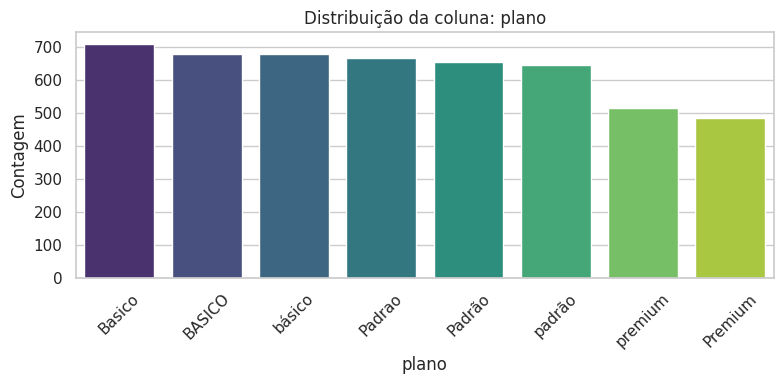


=== Análise da Coluna: ciclo ===


,count
ciclo,
Mensal,3794
Anual,1231


/tmp/ipykernel_490/3798784945.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")


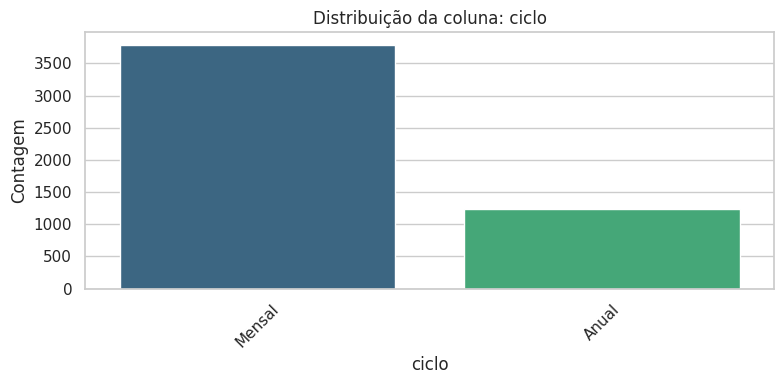


Nota: As seguintes colunas não foram encontradas no DataFrame: ['canal_aquisição', 'região']


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

colunas_analise = ['plano', 'ciclo', 'região', 'canal_aquisição']

# Verificar quais colunas realmente existem no DataFrame
colunas_existentes = [col for col in colunas_analise if col in df.columns]

# Configurar o estilo dos gráficos
sns.set_theme(style="whitegrid")

for col in colunas_existentes:
    print(f"\n=== Análise da Coluna: {col} ===")

    # Contagem de valores únicos (incluindo nulos se houver)
    contagem = df[col].value_counts(dropna=False)
    display(contagem.to_frame())

    # Gerar o gráfico de barras
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette="viridis")
    plt.title(f"Distribuição da coluna: {col}")
    plt.xlabel(col)
    plt.ylabel("Contagem")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Avisar caso alguma coluna solicitada não exista
colunas_faltantes = list(set(colunas_analise) - set(colunas_existentes))
if colunas_faltantes:
    print(f"\nNota: As seguintes colunas não foram encontradas no DataFrame: {colunas_faltantes}")

### 5. Tratamento de Colunas e Nova Análise de Distribuição
Como algumas colunas possuem caracteres especiais ou acentos no arquivo original, vamos normalizar os nomes das colunas do DataFrame (removendo acentos) e padronizar os textos da coluna `plano` para que a análise fique correta.

Colunas após normalização: ['cliente_id', 'idade', 'plano', 'ciclo', 'valor_mensal', 'regiao', 'canal_aquisicao', 'nps', 'data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'motivo_cancelamento', 'churn']

=== Análise da Coluna: plano ===


,count
plano,
basico,2062
padrao,1965
premium,998


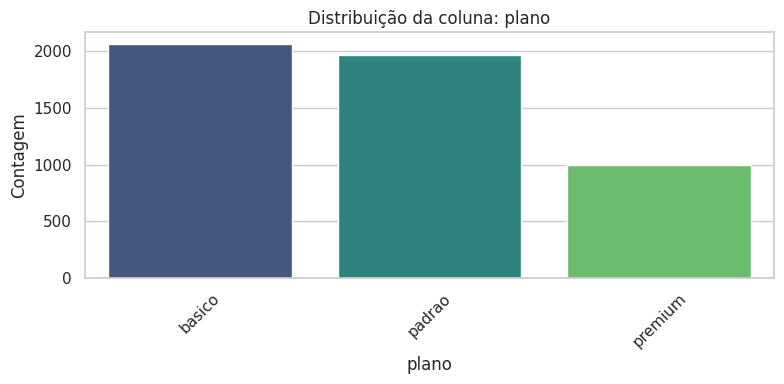


=== Análise da Coluna: ciclo ===


,count
ciclo,
Mensal,3794
Anual,1231


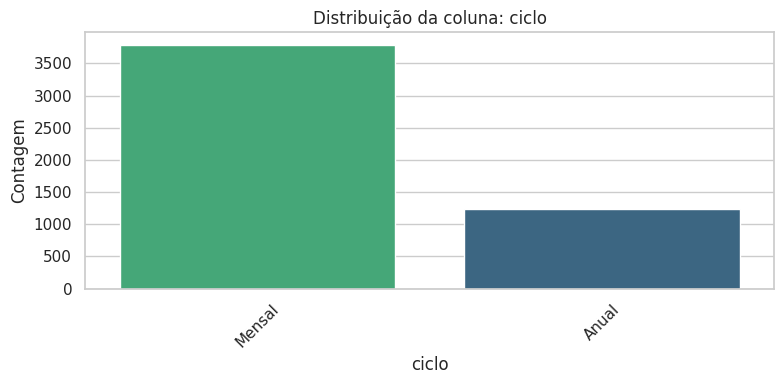


=== Análise da Coluna: regiao ===


,count
regiao,
Sudeste,2057
Nordeste,964
Sul,938
Centro-Oeste,488
Norte,408
?,170


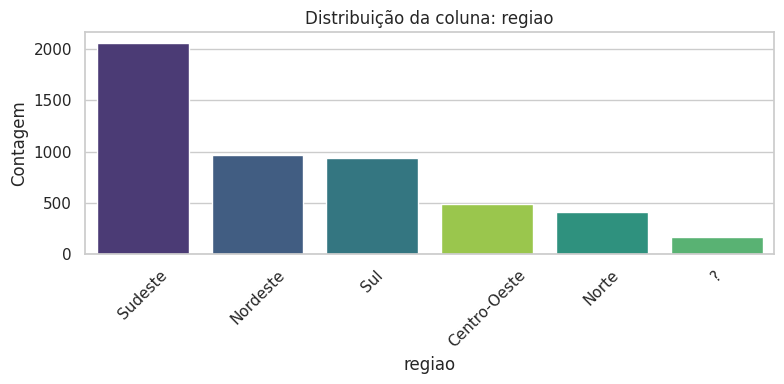


=== Análise da Coluna: canal_aquisicao ===


,count
canal_aquisicao,
Organico,781
orgânico,729
Indicacao,556
IG,529
indicação,526
Instagram,519
instagram,499
Google,452
google,434


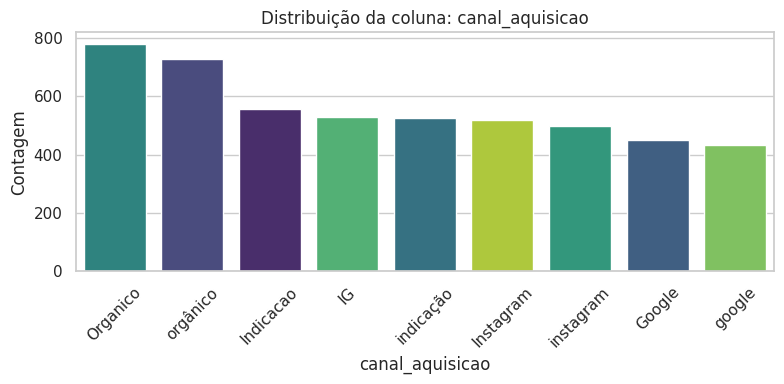

In [30]:
import unicodedata
import matplotlib.pyplot as plt
import seaborn as sns

# Função para remover acentos e caracteres especiais dos nomes das colunas
def normalizar_coluna(col):
    col = col.lower().strip()
    nfkd_form = unicodedata.normalize('NFKD', col)
    return "".join([c for c in nfkd_form if not unicodedata.combining(c)])

# Aplicar normalização nos nomes das colunas
df.columns = [normalizar_coluna(col) for col in df.columns]
print("Colunas após normalização:", list(df.columns))

# Padronizar a coluna 'plano' (remover acentos e colocar em minúsculo)
if 'plano' in df.columns:
    df['plano'] = df['plano'].astype(str).apply(normalizar_coluna)

# Definir as colunas desejadas já normalizadas
colunas_desejadas = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

sns.set_theme(style="whitegrid")

for col in colunas_desejadas:
    if col in df.columns:
        print(f"\n=== Análise da Coluna: {col} ===")

        # Exibir a contagem e valores únicos
        contagem = df[col].value_counts(dropna=False)
        display(contagem.to_frame())

        # Plotar o gráfico de barras correspondente
        plt.figure(figsize=(8, 4))
        sns.countplot(data=df, x=col, order=contagem.index, palette="viridis", hue=col, legend=False)
        plt.title(f"Distribuição da coluna: {col}")
        plt.xlabel(col)
        plt.ylabel("Contagem")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    else:
        print(f"\nAviso: A coluna '{col}' não existe no DataFrame.")

### 6. Respondendo às Perguntas e Tratando os Dados
Vamos executar os passos solicitados para limpar e entender melhor a qualidade dos nossos dados.

In [31]:
# 1. Quantos nulos tem nas colunas?
print("=== 1. Quantidade de valores nulos por coluna ===")
valores_nulos = df.isnull().sum()
display(valores_nulos.to_frame(name='Total Nulos'))

# 2. Exemplo do DataFrame quando a coluna regiao é "?"
print("\n=== 2. Exemplo de registros onde a região é '?' ===")
filtro_interrogacao = df[df['regiao'] == '?']
print(f"Total de linhas com '?': {len(filtro_interrogacao)}")
display(filtro_interrogacao.head(5))

# 3. Padronização da coluna 'plano'
# (Como a célula anterior já normalizou para minúsculo e sem acento, aplicaremos o mapeamento correspondente)
print("\n=== 3. Padronizando a coluna 'plano' ===")
mapeamento_plano = {
    'basico': 'básico',
    'padrao': 'padrão',
    'premium': 'premium'
}
df['plano'] = df['plano'].map(mapeamento_plano).fillna(df['plano'])
print("Valores únicos de 'plano' após ajuste:", df['plano'].unique())

# 4. Padronização da coluna 'canal_aquisicao'
# Vamos primeiro limpar espaços em branco e colocar em minúsculo para facilitar a substituição uniforme
print("\n=== 4. Padronizando a coluna 'canal_aquisicao' ===")
df['canal_aquisicao'] = df['canal_aquisicao'].astype(str).str.lower().str.strip()

mapeamento_canal = {
    'organico': 'orgânico',
    'indicacao': 'indicação',
    'ig': 'instagram',
    'instagram': 'instagram',
    'google': 'google'
}
df['canal_aquisicao'] = df['canal_aquisicao'].map(mapeamento_canal).fillna(df['canal_aquisicao'])
print("Valores únicos de 'canal_aquisicao' após ajuste:", df['canal_aquisicao'].unique())

=== 1. Quantidade de valores nulos por coluna ===


,Total Nulos
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,0
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509



=== 2. Exemplo de registros onde a região é '?' ===
Total de linhas com '?': 170


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
6,4918,37,basico,Mensal,19.9,?,instagram,4,2023-10-12,2023-12-28,2023-12-09,2024-01-31,5,29.6,problema tecnico,1
10,4356,30,basico,Mensal,19.9,?,Organico,8,2020-12-22,NaN,2024-01-11,2024-01-31,15,900.0,NaN,0
34,1433,56,padrao,Anual,3490.0,?,orgânico,9,2023-04-14,NaN,2024-01-22,2024-01-31,11,180.4,NaN,0
68,5259,41,padrao,Mensal,34.9,?,google,5,2023-05-03,NaN,2024-01-28,2024-01-31,8,139.9,NaN,0
135,2171,42,padrao,Mensal,3490.0,?,orgânico,10,2021-04-16,NaN,2024-01-06,2024-01-31,10,505.2,NaN,0



=== 3. Padronizando a coluna 'plano' ===
Valores únicos de 'plano' após ajuste: ['básico' 'padrão' 'premium']

=== 4. Padronizando a coluna 'canal_aquisicao' ===
Valores únicos de 'canal_aquisicao' após ajuste: ['indicação' 'orgânico' 'google' 'instagram']


### 7. Substituindo Interrogações '?' por Nulos (NaN)
Vamos substituir todas as strings `'?'` por valores nulos reais do pandas (`pd.NA` ou `np.nan`) para manter a consistência dos dados nulos.

In [32]:
import numpy as np

# Substituir todas as ocorrências de '?' por NaN
df = df.replace('?', np.nan)

# Verificar novamente a contagem de valores nulos após a substituição
print("=== Contagem de nulos após substituir '?' por NaN ===")
valores_nulos_novos = df.isnull().sum()
display(valores_nulos_novos.to_frame(name='Total Nulos Atualizado'))

=== Contagem de nulos após substituir '?' por NaN ===


,Total Nulos Atualizado
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,170
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [33]:
df.isnull().sum()

,0
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,170
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [36]:
# 1. Converter colunas de data para o tipo datetime
for col in ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

# 2. Recriar as colunas de diferença de dias
date_cols = [col for col in df.columns if 'data' in col and df[col].dtype == '<M8[ns]']
from itertools import combinations
for col1, col2 in combinations(date_cols, 2):
    new_col_name = f"dias_{col1.replace('data_', '')}_desde_{col2.replace('data_', '')}"
    # Remover colunas duplicadas se já existirem
    if new_col_name in df.columns:
        df.drop(columns=[new_col_name], inplace=True)
    df[new_col_name] = (df[col2] - df[col1]).dt.days

# 3. Criar 'dias_ultimo_acesso_desde_assinatura'
# (data_ultimo_acesso - data_assinatura) == - (data_assinatura - data_ultimo_acesso)
if 'dias_assinatura_desde_ultimo_acesso' in df.columns:
    df['dias_ultimo_acesso_desde_assinatura'] = -df['dias_assinatura_desde_ultimo_acesso']

# 4. Criar df_dias_validos
# Clientes onde dias_ultimo_acesso_desde_assinatura é positivo, zero ou nulo
df_dias_validos = df[
    (df['dias_ultimo_acesso_desde_assinatura'].isna()) |
    (df['dias_ultimo_acesso_desde_assinatura'] >= 0)
].copy()

# 5. Criar df_final
# Remover clientes com idade < 18 ou > 90 de df_dias_validos
df_final = df_dias_validos[
    (df_dias_validos['idade'] >= 18) &
    (df_dias_validos['idade'] <= 90)
].copy()

# 6. Recriar colunas de engenharia de recursos em df_final
# Remover as colunas existentes se elas estiverem presentes em df_final antes de recriar
colunas_a_remover_final = ['recencia', 'meses_assinatura', 'receita_acumulada']
df_final.drop(columns=[col for col in colunas_a_remover_final if col in df_final.columns], inplace=True)

# Recriar a coluna 'recencia'
# recencia = diferença data_ultimo_acesso - data_extracao (negativo de 'dias_ultimo_acesso_desde_extracao')
df_final['recencia'] = -df_final['dias_ultimo_acesso_desde_extracao']

# Recriar a coluna 'meses_assinatura'
meses_assinatura_cancelados = -df_final['dias_assinatura_desde_cancelamento'] / 30
meses_assinatura_ativos = -df_final['dias_assinatura_desde_extracao'] / 30
df_final['meses_assinatura'] = meses_assinatura_cancelados.fillna(meses_assinatura_ativos)

# Recriar a coluna 'receita_acumulada'
df_final['receita_acumulada'] = df_final['valor_mensal'] * df_final['meses_assinatura']

print("Colunas do DataFrame `df_final` após a adição:")
display(df_final.columns)

print("\nExemplo das novas colunas no DataFrame `df_final`:")
display(df_final[['cliente_id', 'valor_mensal', 'recencia', 'meses_assinatura', 'receita_acumulada']].head())

Colunas do DataFrame `df_final` após a adição:


Index(['cliente_id', 'idade', 'plano', 'ciclo', 'valor_mensal', 'regiao',
       'canal_aquisicao', 'nps', 'data_assinatura', 'data_cancelamento',
       'data_ultimo_acesso', 'data_extracao', 'dias_ativos_ult_mes',
       'horas_assistidas_total', 'motivo_cancelamento', 'churn',
       'dias_ultimo_acesso_desde_assinatura',
       'dias_assinatura_desde_cancelamento',
       'dias_assinatura_desde_ultimo_acesso', 'dias_assinatura_desde_extracao',
       'dias_cancelamento_desde_ultimo_acesso',
       'dias_cancelamento_desde_extracao', 'dias_ultimo_acesso_desde_extracao',
       'recencia', 'meses_assinatura', 'receita_acumulada'],
      dtype='object')


Exemplo das novas colunas no DataFrame `df_final`:


,cliente_id,valor_mensal,recencia,meses_assinatura,receita_acumulada
11,3426,55.9,-213.0,-3.000000,-167.700000
80,4291,34.9,NaN,-22.666667,-791.066667
192,2370,3490.0,NaN,-4.633333,-16170.333333
197,5082,55.9,NaN,-7.766667,-434.156667
353,1873,34.9,NaN,-17.866667,-623.546667


In [43]:
print("Tabela `df_final` após todos os passos anteriores:")
display(df_final.head())

Tabela `df_final` após todos os passos anteriores:


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ultimo_acesso_desde_assinatura,dias_assinatura_desde_cancelamento,dias_assinatura_desde_ultimo_acesso,dias_assinatura_desde_extracao,dias_cancelamento_desde_ultimo_acesso,dias_cancelamento_desde_extracao,dias_ultimo_acesso_desde_extracao,recencia,meses_assinatura,receita_acumulada
11,3426,48,premium,Anual,55.9,Nordeste,indicação,5,2023-08-18,2023-11-16,...,47.0,90.0,-47.0,166,-137.0,76.0,213.0,-213.0,-3.000000,-167.700000
80,4291,47,padrão,Mensal,34.9,Sul,instagram,3,2022-03-22,NaT,...,NaN,NaN,NaN,680,NaN,NaN,NaN,NaN,-22.666667,-791.066667
192,2370,54,padrão,Mensal,3490.0,Norte,indicação,5,2023-09-14,NaT,...,NaN,NaN,NaN,139,NaN,NaN,NaN,NaN,-4.633333,-16170.333333
197,5082,33,premium,Anual,55.9,Norte,orgânico,7,2023-06-12,NaT,...,NaN,NaN,NaN,233,NaN,NaN,NaN,NaN,-7.766667,-434.156667
353,1873,29,padrão,Mensal,34.9,Sudeste,orgânico,6,2022-08-13,NaT,...,NaN,NaN,NaN,536,NaN,NaN,NaN,NaN,-17.866667,-623.546667


In [42]:
# Remover as colunas existentes se elas estiverem presentes
colunas_a_remover = ['recencia', 'meses_assinatura', 'receita_acumulada']
df_final = df_final.drop(columns=[col for col in colunas_a_remover if col in df_final.columns])

print("Colunas 'recencia', 'meses_assinatura' e 'receita_acumulada' foram removidas (se existiam).")

# 1. Recriar a coluna 'recencia'
# recencia = diferença data_ultimo_acesso - data_extracao
# 'dias_ultimo_acesso_desde_extracao' = (data_extracao - data_ultimo_acesso).dt.days
# Portanto, (data_ultimo_acesso - data_extracao).dt.days é o negativo de 'dias_ultimo_acesso_desde_extracao'
df_final['recencia'] = -df_final['dias_ultimo_acesso_desde_extracao']

# 2. Recriar a coluna 'meses_assinatura'
# meses_assinatura = (diferença data_assinatura-data_cancelamento)/30 se data_cancelamento for nula (cliente ativo), use (diferença data_assinatura-data_extracao)/30 no lugar

# Para clientes com data_cancelamento (já cancelados)
# 'dias_assinatura_desde_cancelamento' = (data_cancelamento - data_assinatura).dt.days
# Diferença (data_assinatura - data_cancelamento) será = -'dias_assinatura_desde_cancelamento'
meses_assinatura_cancelados = -df_final['dias_assinatura_desde_cancelamento'] / 30

# Para clientes sem data_cancelamento (ativos)
# 'dias_assinatura_desde_extracao' = (data_extracao - data_assinatura).dt.days
# Diferença (data_assinatura - data_extracao) será = -'dias_assinatura_desde_extracao'
meses_assinatura_ativos = -df_final['dias_assinatura_desde_extracao'] / 30

# Preencher valores nulos (onde data_cancelamento era nula) com os cálculos para clientes ativos
df_final['meses_assinatura'] = meses_assinatura_cancelados.fillna(meses_assinatura_ativos)

# 3. Recriar a coluna 'receita_acumulada'
df_final['receita_acumulada'] = df_final['valor_mensal'] * df_final['meses_assinatura']

print("Novas colunas 'recencia', 'meses_assinatura' e 'receita_acumulada' foram recriadas no DataFrame `df_final`.")

# Exibir as primeiras linhas com as novas colunas para verificação
display(df_final[['cliente_id', 'valor_mensal', 'recencia', 'meses_assinatura', 'receita_acumulada', 'data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']].head())

Colunas 'recencia', 'meses_assinatura' e 'receita_acumulada' foram removidas (se existiam).
Novas colunas 'recencia', 'meses_assinatura' e 'receita_acumulada' foram recriadas no DataFrame `df_final`.


,cliente_id,valor_mensal,recencia,meses_assinatura,receita_acumulada,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao
11,3426,55.9,-213.0,-3.000000,-167.700000,2023-08-18,2023-11-16,2023-07-02,2024-01-31
80,4291,34.9,NaN,-22.666667,-791.066667,2022-03-22,NaT,NaT,2024-01-31
192,2370,3490.0,NaN,-4.633333,-16170.333333,2023-09-14,NaT,NaT,2024-01-31
197,5082,55.9,NaN,-7.766667,-434.156667,2023-06-12,NaT,NaT,2024-01-31
353,1873,34.9,NaN,-17.866667,-623.546667,2022-08-13,NaT,NaT,2024-01-31


In [58]:
print("Primeiras 5 linhas de `df_analise`:")
display(df_analise.head())

Primeiras 5 linhas de `df_analise`:


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ultimo_acesso_desde_assinatura,dias_assinatura_desde_cancelamento,dias_assinatura_desde_ultimo_acesso,dias_assinatura_desde_extracao,dias_cancelamento_desde_ultimo_acesso,dias_cancelamento_desde_extracao,dias_ultimo_acesso_desde_extracao,recencia,meses_assinatura,receita_acumulada


In [59]:
print("DataFrame `df_analise`:")
display(df_analise)

DataFrame `df_analise`:


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ultimo_acesso_desde_assinatura,dias_assinatura_desde_cancelamento,dias_assinatura_desde_ultimo_acesso,dias_assinatura_desde_extracao,dias_cancelamento_desde_ultimo_acesso,dias_cancelamento_desde_extracao,dias_ultimo_acesso_desde_extracao,recencia,meses_assinatura,receita_acumulada


In [60]:
print("DataFrame `df_final` atualizado com 'recencia', 'meses_assinatura' e 'receita_acumulada':")
display(df_final.head())

DataFrame `df_final` atualizado com 'recencia', 'meses_assinatura' e 'receita_acumulada':


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ultimo_acesso_desde_assinatura,dias_assinatura_desde_cancelamento,dias_assinatura_desde_ultimo_acesso,dias_assinatura_desde_extracao,dias_cancelamento_desde_ultimo_acesso,dias_cancelamento_desde_extracao,dias_ultimo_acesso_desde_extracao,recencia,meses_assinatura,receita_acumulada
11,3426,48,premium,Anual,55.9,Nordeste,indicação,5,2023-08-18,2023-11-16,...,47.0,90.0,-47.0,166,-137.0,76.0,213.0,-213.0,-3.000000,-167.700000
80,4291,47,padrão,Mensal,34.9,Sul,instagram,3,2022-03-22,NaT,...,NaN,NaN,NaN,680,NaN,NaN,NaN,NaN,-22.666667,-791.066667
192,2370,54,padrão,Mensal,3490.0,Norte,indicação,5,2023-09-14,NaT,...,NaN,NaN,NaN,139,NaN,NaN,NaN,NaN,-4.633333,-16170.333333
197,5082,33,premium,Anual,55.9,Norte,orgânico,7,2023-06-12,NaT,...,NaN,NaN,NaN,233,NaN,NaN,NaN,NaN,-7.766667,-434.156667
353,1873,29,padrão,Mensal,34.9,Sudeste,orgânico,6,2022-08-13,NaT,...,NaN,NaN,NaN,536,NaN,NaN,NaN,NaN,-17.866667,-623.546667


In [61]:
print("DataFrame `df` (clientes_base.csv) completo:")
display(df)

DataFrame `df` (clientes_base.csv) completo:


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5020,1789,21,Padrão,Mensal,34.9,Nordeste,indicação,8,2022-11-22,NaN,2024-01-12,2024-01-31,13,424.9,NaN,0
5021,1968,42,Padrao,Mensal,34.9,Sudeste,indicação,6,2021-07-26,NaN,2024-01-07,2024-01-31,15,900.0,NaN,0
5022,2667,66,Padrão,Mensal,34.9,Sudeste,orgânico,9,2023-05-26,NaN,2024-01-25,2024-01-31,14,232.2,NaN,0
5023,4321,39,básico,Mensal,19.9,Sudeste,indicação,7,2022-12-16,NaN,2024-01-04,2024-01-31,16,448.2,NaN,0


In [38]:
print("\n=== Estatísticas Descritivas para 'recencia', 'meses_assinatura' e 'receita_acumulada' ===")
display(df_final[['recencia', 'meses_assinatura', 'receita_acumulada']].describe())


=== Estatísticas Descritivas para 'recencia', 'meses_assinatura' e 'receita_acumulada' ===


,recencia,meses_assinatura,receita_acumulada
count,10.000000,60.000000,60.000000
mean,-48.700000,-10.243333,-4309.931333
std,58.897368,8.243201,16392.547368
min,-213.000000,-29.766667,-100433.666667
25%,-37.500000,-17.108333,-642.347500
50%,-34.500000,-7.983333,-268.525000
75%,-32.250000,-3.100000,-108.007500
max,-1.000000,-0.033333,-0.663333


In [39]:
print("\n=== Criando df_analise com base na condição ===")
# A condição 'data_assinatura - data_extracao >= 220' é equivalente a '-dias_assinatura_desde_extracao >= 220'
df_analise = df_final[df_final['dias_assinatura_desde_extracao'] <= -220].copy()

print("Primeiras linhas de df_analise:")
display(df_analise.head())

print(f"Forma de df_analise: {df_analise.shape}")


=== Criando df_analise com base na condição ===
Primeiras linhas de df_analise:


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ultimo_acesso_desde_assinatura,dias_assinatura_desde_cancelamento,dias_assinatura_desde_ultimo_acesso,dias_assinatura_desde_extracao,dias_cancelamento_desde_ultimo_acesso,dias_cancelamento_desde_extracao,dias_ultimo_acesso_desde_extracao,recencia,meses_assinatura,receita_acumulada


Forma de df_analise: (0, 26)


## Análise da Relação entre Churn e Variáveis Relevantes

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

# Definindo as variáveis para análise
numerical_cols = ['idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'dias_assinatura_desde_extracao', 'dias_ultimo_acesso_desde_extracao', 'recencia', 'meses_assinatura', 'receita_acumulada']
categorical_cols = ['plano', 'ciclo', 'regiao', 'canal_aquisicao', 'motivo_cancelamento']

# --- Verificação inicial da relação entre 'motivo_cancelamento' e 'churn' ---
print("=== Verificando relação entre 'motivo_cancelamento' e 'churn' ===")
# Clientes com motivo de cancelamento não nulo devem ter churn = 1
motivos_e_churn_0 = df_analise[(df_analise['motivo_cancelamento'].notna()) & (df_analise['churn'] == 0)]
print(f"Número de clientes com 'motivo_cancelamento' preenchido, mas 'churn' = 0: {len(motivos_e_churn_0)}")
if len(motivos_e_churn_0) > 0:
    print("Exemplos:")
    display(motivos_e_churn_0[['churn', 'motivo_cancelamento']].head())

# Clientes com churn = 1, mas 'motivo_cancelamento' é NaN
churn_1_e_motivo_nan = df_analise[(df_analise['churn'] == 1) & (df_analise['motivo_cancelamento'].isna())]
print(f"Número de clientes com 'churn' = 1, mas 'motivo_cancelamento' é NaN: {len(churn_1_e_motivo_nan)}")
if len(churn_1_e_motivo_nan) > 0:
    print("Exemplos:")
    display(churn_1_e_motivo_nan[['churn', 'motivo_cancelamento']].head())
else:
    print("Todos os clientes com CHURN = 1 possuem 'motivo_cancelamento' preenchido.")

=== Verificando relação entre 'motivo_cancelamento' e 'churn' ===
Número de clientes com 'motivo_cancelamento' preenchido, mas 'churn' = 0: 0
Número de clientes com 'churn' = 1, mas 'motivo_cancelamento' é NaN: 0
Todos os clientes com CHURN = 1 possuem 'motivo_cancelamento' preenchido.


### Análise de Variáveis Numéricas vs. Churn


=== Análise da Variável Numérica: idade vs. Churn ===


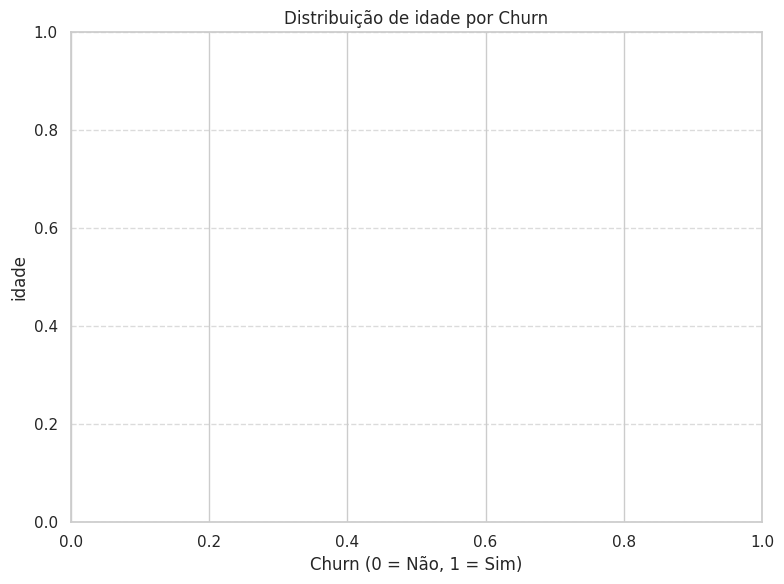

Correlação entre idade e Churn: nan
Não há dados suficientes para realizar o teste t para idade.

=== Análise da Variável Numérica: valor_mensal vs. Churn ===


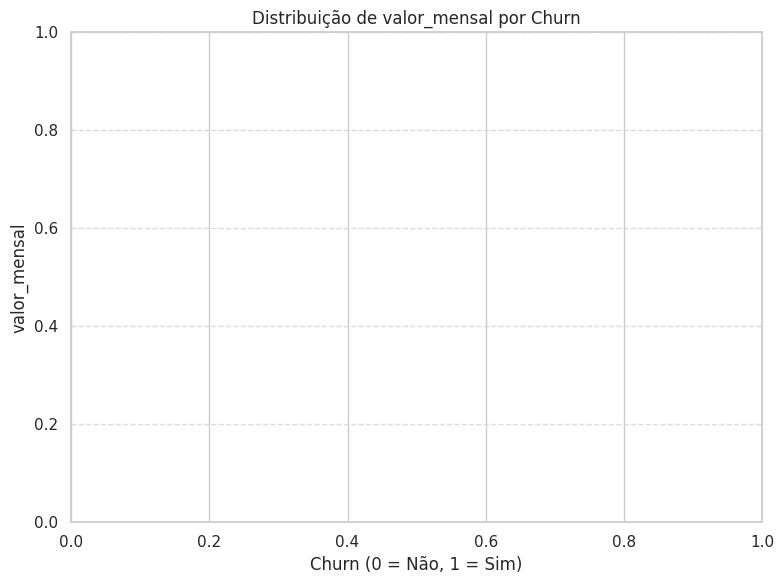

Correlação entre valor_mensal e Churn: nan
Não há dados suficientes para realizar o teste t para valor_mensal.

=== Análise da Variável Numérica: nps vs. Churn ===


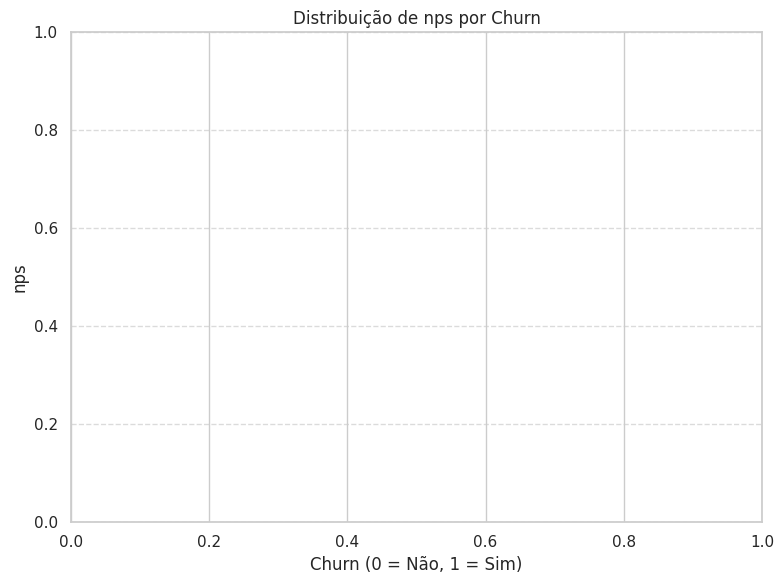

Correlação entre nps e Churn: nan
Não há dados suficientes para realizar o teste t para nps.

=== Análise da Variável Numérica: dias_ativos_ult_mes vs. Churn ===


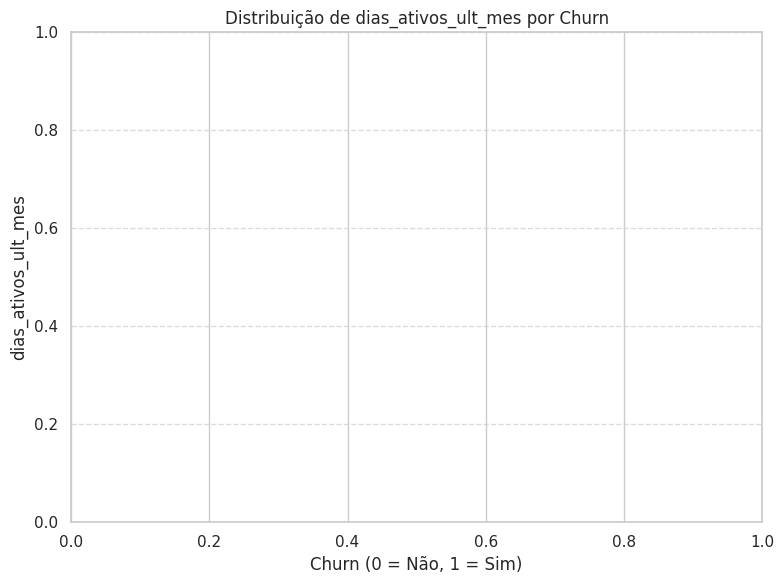

Correlação entre dias_ativos_ult_mes e Churn: nan
Não há dados suficientes para realizar o teste t para dias_ativos_ult_mes.

=== Análise da Variável Numérica: horas_assistidas_total vs. Churn ===


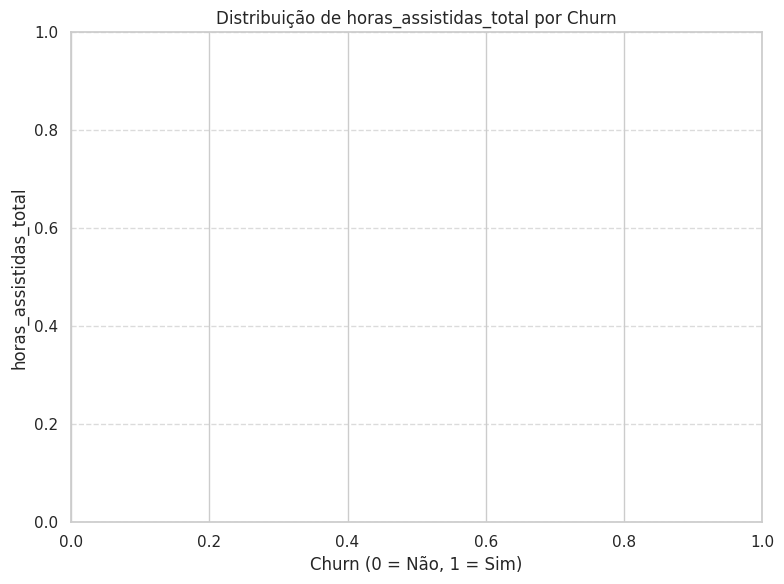

Correlação entre horas_assistidas_total e Churn: nan
Não há dados suficientes para realizar o teste t para horas_assistidas_total.

=== Análise da Variável Numérica: dias_assinatura_desde_extracao vs. Churn ===


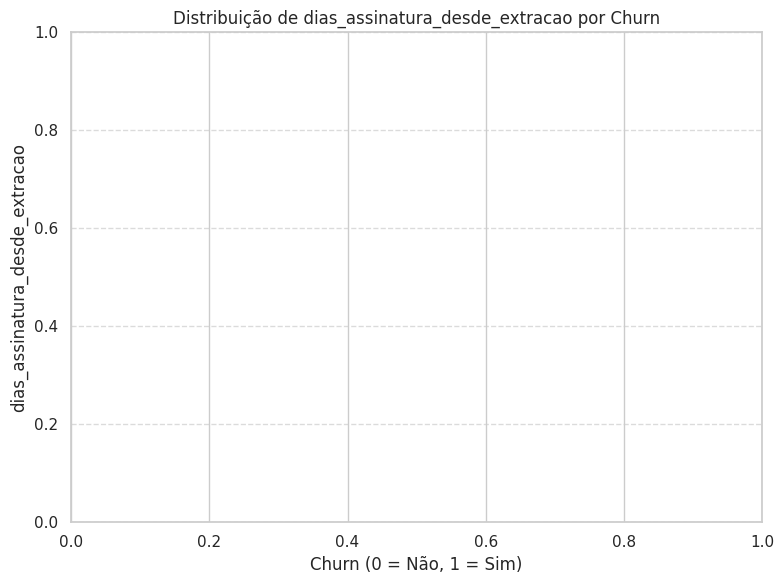

Correlação entre dias_assinatura_desde_extracao e Churn: nan
Não há dados suficientes para realizar o teste t para dias_assinatura_desde_extracao.

=== Análise da Variável Numérica: dias_ultimo_acesso_desde_extracao vs. Churn ===


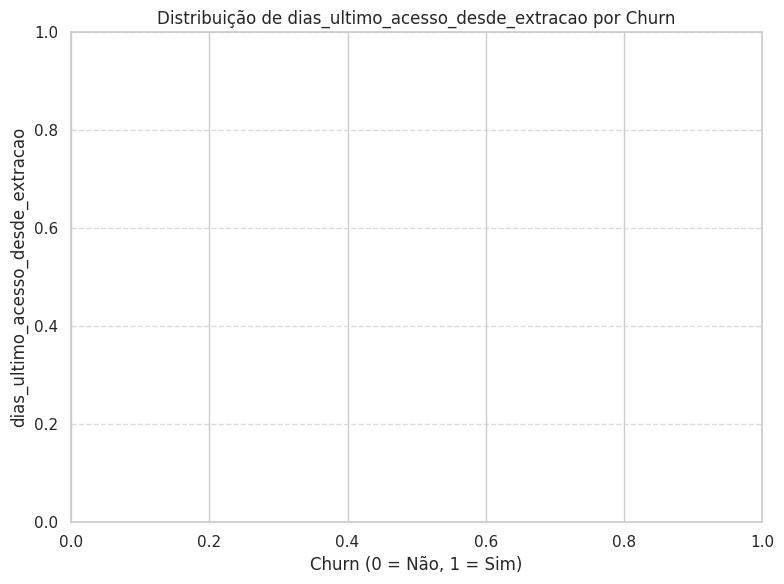

Correlação entre dias_ultimo_acesso_desde_extracao e Churn: nan
Não há dados suficientes para realizar o teste t para dias_ultimo_acesso_desde_extracao.

=== Análise da Variável Numérica: recencia vs. Churn ===


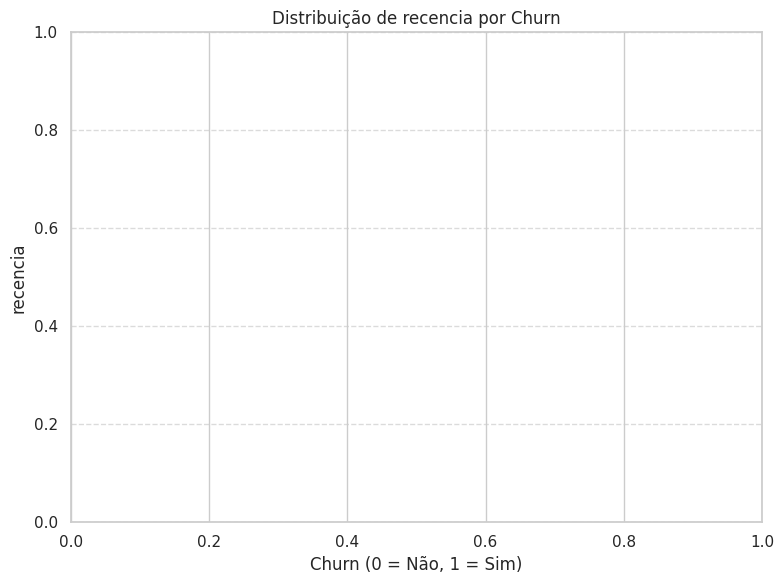

Correlação entre recencia e Churn: nan
Não há dados suficientes para realizar o teste t para recencia.

=== Análise da Variável Numérica: meses_assinatura vs. Churn ===


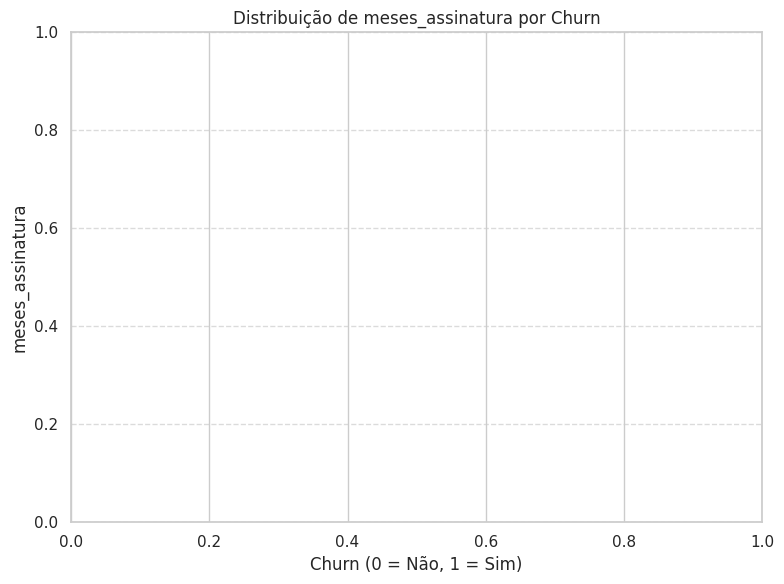

Correlação entre meses_assinatura e Churn: nan
Não há dados suficientes para realizar o teste t para meses_assinatura.

=== Análise da Variável Numérica: receita_acumulada vs. Churn ===


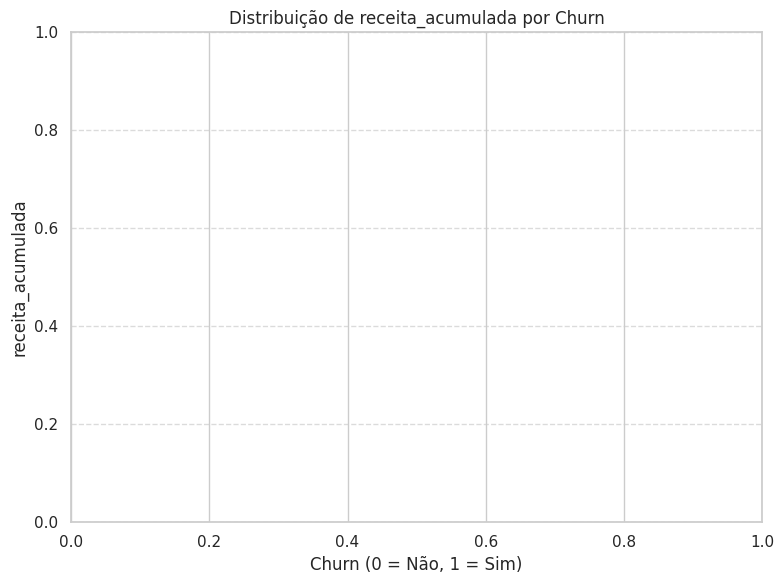

Correlação entre receita_acumulada e Churn: nan
Não há dados suficientes para realizar o teste t para receita_acumulada.


In [41]:
for col in numerical_cols:
    print(f"\n=== Análise da Variável Numérica: {col} vs. Churn ===")

    # Boxplot para visualizar a distribuição da variável numérica para cada grupo de churn
    plt.figure(figsize=(8, 6))
    sns.boxplot(x='churn', y=col, data=df_analise, palette='viridis')
    plt.title(f'Distribuição de {col} por Churn')
    plt.xlabel('Churn (0 = Não, 1 = Sim)')
    plt.ylabel(col)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

    # Calcular a correlação entre a variável numérica e 'churn'
    correlation = df_analise[col].corr(df_analise['churn'])
    print(f"Correlação entre {col} e Churn: {correlation:.4f}")

    # Teste t de Student para comparar as médias dos grupos churn (0 e 1)
    # Separar os dados para cada grupo de churn
    churn_0 = df_analise[df_analise['churn'] == 0][col].dropna()
    churn_1 = df_analise[df_analise['churn'] == 1][col].dropna()

    if len(churn_0) > 1 and len(churn_1) > 1:
        # Realizar o teste t de Student (assumindo variâncias desiguais)
        t_stat, p_value = stats.ttest_ind(churn_0, churn_1, equal_var=False)
        print(f"Teste t de Student para {col}:")
        print(f"  Estatística t: {t_stat:.4f}")
        print(f"  Valor p: {p_value:.4f}")
        if p_value < 0.05:
            print("  (Diferença estatisticamente significativa entre as médias dos grupos Churn)")
        else:
            print("  (Nenhuma diferença estatisticamente significativa entre as médias dos grupos Churn)")
    else:
        print(f"Não há dados suficientes para realizar o teste t para {col}.")

### Histogramas de Densidade para Variáveis Numéricas por Churn

/tmp/ipykernel_490/1533113208.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=df_analise, x=col, hue='churn', kde=True, stat='density', common_norm=False, palette='coolwarm')


ValueError: `dataset` input should have multiple elements.

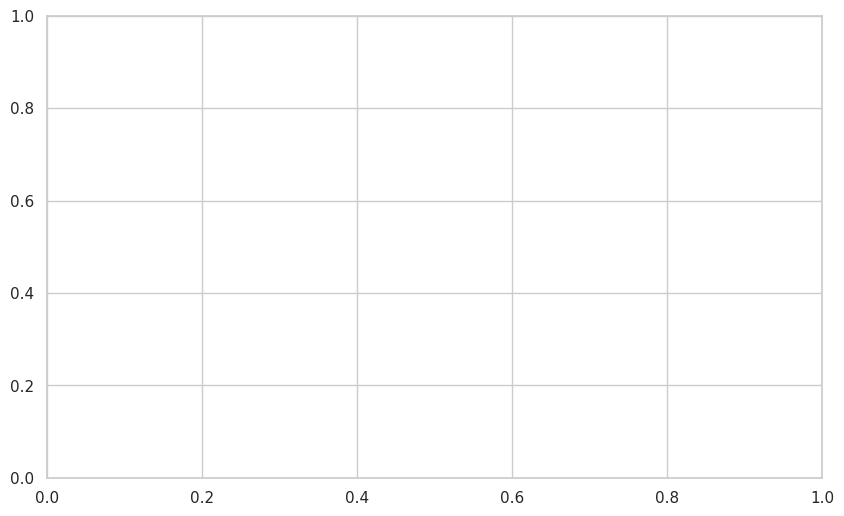

In [54]:
for col in numerical_cols:
    plt.figure(figsize=(10, 6))
    sns.histplot(data=df_analise, x=col, hue='churn', kde=True, stat='density', common_norm=False, palette='coolwarm')
    plt.title(f'Distribuição de Densidade de {col} por Churn')
    plt.xlabel(col)
    plt.ylabel('Densidade')
    plt.legend(title='Churn', labels=['Não (0)', 'Sim (1)'])
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()


### Re-gerando Histogramas de Densidade para Variáveis Numéricas por Churn

In [25]:
for col in numerical_cols:
    plt.figure(figsize=(10, 6))
    sns.histplot(data=df_analise, x=col, hue='churn', kde=True, stat='density', common_norm=False, palette='coolwarm')
    plt.title(f'Distribuição de Densidade de {col} por Churn')
    plt.xlabel(col)
    plt.ylabel('Densidade')
    plt.legend(title='Churn', labels=['Não (0)', 'Sim (1)'])
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

NameError: name 'df_analise' is not defined

<Figure size 1000x600 with 0 Axes>

### Estatísticas Descritivas por Grupo de Churn para Variáveis Numéricas

In [53]:
for col in numerical_cols:
    print(f"\n=== Estatísticas Descritivas para '{col}' por Grupo de Churn ===")
    display(df_analise.groupby('churn')[col].describe())


=== Estatísticas Descritivas para 'idade' por Grupo de Churn ===


,count,mean,std,min,25%,50%,75%,max



=== Estatísticas Descritivas para 'valor_mensal' por Grupo de Churn ===


,count,mean,std,min,25%,50%,75%,max



=== Estatísticas Descritivas para 'nps' por Grupo de Churn ===


...

,count,mean,std,min,25%,50%,75%,max



=== Estatísticas Descritivas para 'meses_assinatura' por Grupo de Churn ===


,count,mean,std,min,25%,50%,75%,max



=== Estatísticas Descritivas para 'receita_acumulada' por Grupo de Churn ===


,count,mean,std,min,25%,50%,75%,max


### Análise de Variáveis Categóricas vs. Churn (Taxa de Churn por Categoria)

In [52]:
# Excluindo 'motivo_cancelamento' da análise de variáveis categóricas, pois ela é diretamente ligada ao churn (se preenchida, indica churn=1).
categorical_cols_for_churn_rate = [col for col in categorical_cols if col != 'motivo_cancelamento']

for col in categorical_cols_for_churn_rate:
    print(f"\n=== Taxa de Churn por Categoria para '{col}' ===")
    churn_rate = df_analise.groupby(col)['churn'].value_counts(normalize=True).unstack(fill_value=0) * 100

    # Garantir que a coluna '1' (churn = sim) existe e renomeá-la para 'Taxa de Churn (%)'
    if 1 in churn_rate.columns:
        churn_rate_df = churn_rate[[1]].rename(columns={1: 'Taxa de Churn (%)'})
    else:
        # Se não houver churn = 1 para a categoria, a taxa de churn é 0
        churn_rate_df = pd.DataFrame(0, index=churn_rate.index, columns=['Taxa de Churn (%)'])

    display(churn_rate_df.sort_values(by='Taxa de Churn (%)', ascending=False))


=== Taxa de Churn por Categoria para 'plano' ===


,Taxa de Churn (%)
plano,



=== Taxa de Churn por Categoria para 'ciclo' ===


,Taxa de Churn (%)
ciclo,



=== Taxa de Churn por Categoria para 'regiao' ===


,Taxa de Churn (%)
regiao,



=== Taxa de Churn por Categoria para 'canal_aquisicao' ===


,Taxa de Churn (%)
canal_aquisicao,


In [63]:
# Redefinindo df_analise para ser igual a df_final, removendo a filtragem que o deixou vazio
df_analise = df_final.copy()

print("Primeiras 5 linhas do `df_analise` (agora com dados):")
display(df_analise.head())

Primeiras 5 linhas do `df_analise` (agora com dados):


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ultimo_acesso_desde_assinatura,dias_assinatura_desde_cancelamento,dias_assinatura_desde_ultimo_acesso,dias_assinatura_desde_extracao,dias_cancelamento_desde_ultimo_acesso,dias_cancelamento_desde_extracao,dias_ultimo_acesso_desde_extracao,recencia,meses_assinatura,receita_acumulada
11,3426,48,premium,Anual,55.9,Nordeste,indicação,5,2023-08-18,2023-11-16,...,47.0,90.0,-47.0,166,-137.0,76.0,213.0,-213.0,-3.000000,-167.700000
80,4291,47,padrão,Mensal,34.9,Sul,instagram,3,2022-03-22,NaT,...,NaN,NaN,NaN,680,NaN,NaN,NaN,NaN,-22.666667,-791.066667
192,2370,54,padrão,Mensal,3490.0,Norte,indicação,5,2023-09-14,NaT,...,NaN,NaN,NaN,139,NaN,NaN,NaN,NaN,-4.633333,-16170.333333
197,5082,33,premium,Anual,55.9,Norte,orgânico,7,2023-06-12,NaT,...,NaN,NaN,NaN,233,NaN,NaN,NaN,NaN,-7.766667,-434.156667
353,1873,29,padrão,Mensal,34.9,Sudeste,orgânico,6,2022-08-13,NaT,...,NaN,NaN,NaN,536,NaN,NaN,NaN,NaN,-17.866667,-623.546667


### Análise de Pareto dos Motivos de Cancelamento

Vamos analisar os `motivo_cancelamento` para identificar as causas mais frequentes de churn, usando o princípio de Pareto (80/20).


=== Contagem de Cancelamentos por Motivo (Normalizado) ===


,motivo,contagem
0,pouco conteudo novo,7
1,preco,5
2,problema tecnico,5
3,concorrente,4
4,falta de tempo,3



=== Tabela de Pareto ===


,motivo,contagem,porcentagem,porcentagem_acumulada
0,pouco conteudo novo,7,29.166667,29.166667
1,preco,5,20.833333,50.000000
2,problema tecnico,5,20.833333,70.833333
3,concorrente,4,16.666667,87.500000
4,falta de tempo,3,12.500000,100.000000



=== Motivos que concentram cerca de 80% dos cancelamentos (até 70.83%) ===


,motivo,contagem,porcentagem,porcentagem_acumulada
0,pouco conteudo novo,7,29.166667,29.166667
1,preco,5,20.833333,50.000000
2,problema tecnico,5,20.833333,70.833333


/tmp/ipykernel_490/167397965.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='motivo', y='contagem', data=tabela_pareto, ax=ax1, palette='viridis')
/tmp/ipykernel_490/167397965.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(tabela_pareto['motivo'], rotation=45, ha='right')


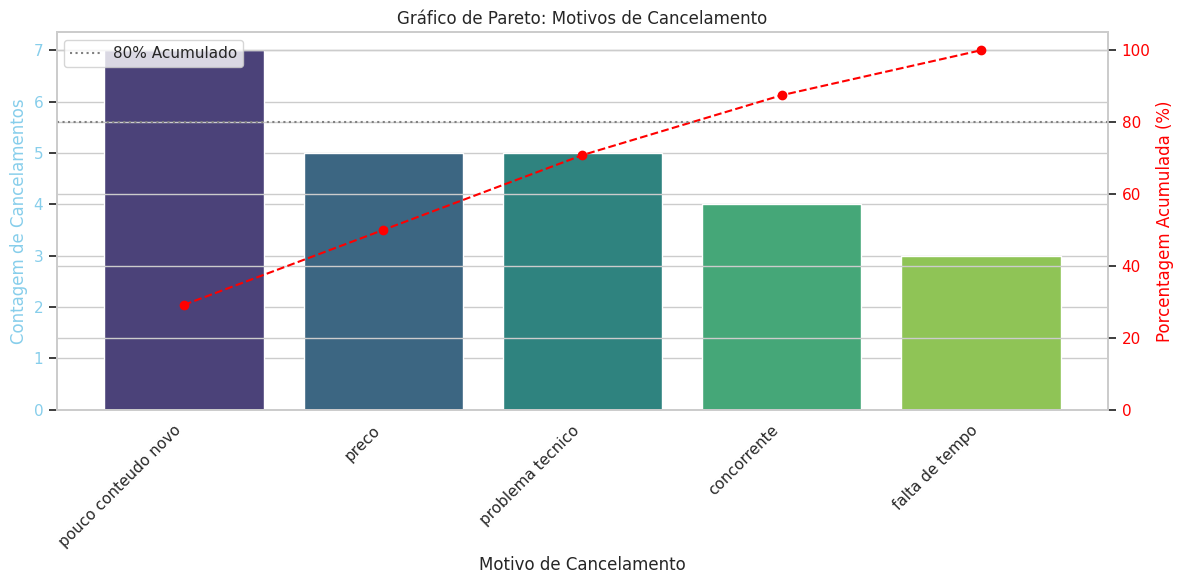

In [64]:
import unicodedata
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Função para normalizar strings (minúsculas, sem acentos, sem espaços extras)
def normalizar_texto(texto):
    if pd.isna(texto):
        return texto
    texto = str(texto).lower().strip()
    nfkd_form = unicodedata.normalize('NFKD', texto)
    return ''.join([c for c in nfkd_form if not unicodedata.combining(c)])

# 1. Normalizar a coluna 'motivo_cancelamento'
df_analise['motivo_cancelamento_normalizado'] = df_analise['motivo_cancelamento'].apply(normalizar_texto)

# 2. Contar cancelamentos por motivo (ignorando nulos)
contagem_motivos = df_analise['motivo_cancelamento_normalizado'].value_counts().reset_index()
contagem_motivos.columns = ['motivo', 'contagem']

print("\n=== Contagem de Cancelamentos por Motivo (Normalizado) ===")
display(contagem_motivos)

# 3. Montar a tabela de Pareto
total_cancelamentos = contagem_motivos['contagem'].sum()
tabela_pareto = contagem_motivos.copy()
tabela_pareto['porcentagem'] = (tabela_pareto['contagem'] / total_cancelamentos) * 100
tabela_pareto['porcentagem_acumulada'] = tabela_pareto['porcentagem'].cumsum()

print("\n=== Tabela de Pareto ===")
display(tabela_pareto)

# 4. Identificar motivos que concentram cerca de 80% dos cancelamentos
motivos_80_percent = tabela_pareto[tabela_pareto['porcentagem_acumulada'] <= 80]

if not motivos_80_percent.empty:
    print(f"\n=== Motivos que concentram cerca de 80% dos cancelamentos (até {motivos_80_percent['porcentagem_acumulada'].iloc[-1]:.2f}%) ===")
    display(motivos_80_percent)
else:
    print("\nNenhum motivo individual atingiu 80% da porcentagem acumulada.")

# 5. Plotar o gráfico de Pareto
fig, ax1 = plt.subplots(figsize=(12, 6))

# Barras para a contagem
sns.barplot(x='motivo', y='contagem', data=tabela_pareto, ax=ax1, palette='viridis')
ax1.set_xlabel('Motivo de Cancelamento')
ax1.set_ylabel('Contagem de Cancelamentos', color='skyblue')
ax1.tick_params(axis='y', labelcolor='skyblue')
ax1.set_title('Gráfico de Pareto: Motivos de Cancelamento')
ax1.set_xticklabels(tabela_pareto['motivo'], rotation=45, ha='right')

# Linha para a porcentagem acumulada
ax2 = ax1.twinx()
ax2.plot(tabela_pareto['motivo'], tabela_pareto['porcentagem_acumulada'], color='red', marker='o', linestyle='--')
ax2.set_ylabel('Porcentagem Acumulada (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylim(0, 105)

# Linha de referência em 80%
ax2.axhline(y=80, color='gray', linestyle=':', label='80% Acumulado')
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

### Análise de Funil de Conversão do Onboarding

Agora vamos carregar e pré-processar o arquivo `funil_eventos.csv` para a análise do funil.

In [65]:
# Caminho do arquivo funil_eventos.csv
caminho_funil_eventos = os.path.join(caminho_pasta, 'funil_eventos.csv')

# Carregar o arquivo funil_eventos.csv
try:
    df_funil = pd.read_csv(caminho_funil_eventos)
    print(f"Arquivo '{os.path.basename(caminho_funil_eventos)}' carregado com sucesso.")
except FileNotFoundError:
    print(f"Erro: O arquivo '{os.path.basename(caminho_funil_eventos)}' não foi encontrado em '{caminho_pasta}'.")
    df_funil = pd.DataFrame() # Criar DataFrame vazio em caso de erro

# Remover duplicatas
if not df_funil.empty:
    linhas_antes = df_funil.shape[0]
    df_funil.drop_duplicates(inplace=True)
    linhas_depois = df_funil.shape[0]
    print(f"Removidas {linhas_antes - linhas_depois} linhas duplicadas.")

    print("\nPrimeiras 5 linhas do DataFrame `df_funil` após carregamento e remoção de duplicatas:")
    display(df_funil.head())
else:
    print("Não foi possível carregar o DataFrame de funil.")

Arquivo 'funil_eventos.csv' carregado com sucesso.
Removidas 50 linhas duplicadas.

Primeiras 5 linhas do DataFrame `df_funil` após carregamento e remoção de duplicatas:


,cliente_id,etapa
0,2165,assistiu_1a_aula
1,3269,criou_conta
2,4589,criou_conta
3,5228,visitou_site
4,4620,assistiu_1a_aula


### Processamento e Análise do Funil de Conversão

Vamos agora padronizar a coluna `etapa` e construir a análise do funil de conversão.

Valores únicos da coluna 'etapa' após padronização:


array(['assistiu_1a_aula', 'criou_conta', 'visitou_site', 'renovou',
       'assinou_plano'], dtype=object)


=== Tabela de Funil de Conversão ===


,usuarios,conversao_anterior,conversao_topo
etapa,,,
visitou_site,5000,100.000000,100.00
criou_conta,3377,67.540000,67.54
assistiu_1a_aula,2698,79.893397,53.96
assinou_plano,1066,39.510749,21.32
renovou,695,65.196998,13.90



O maior gargalo do funil é na etapa 'assinou_plano' com uma taxa de conversão de 39.51% da etapa anterior.


/tmp/ipykernel_490/4215817548.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='usuarios', y='etapa', data=plot_data.sort_values(by='usuarios', ascending=True),


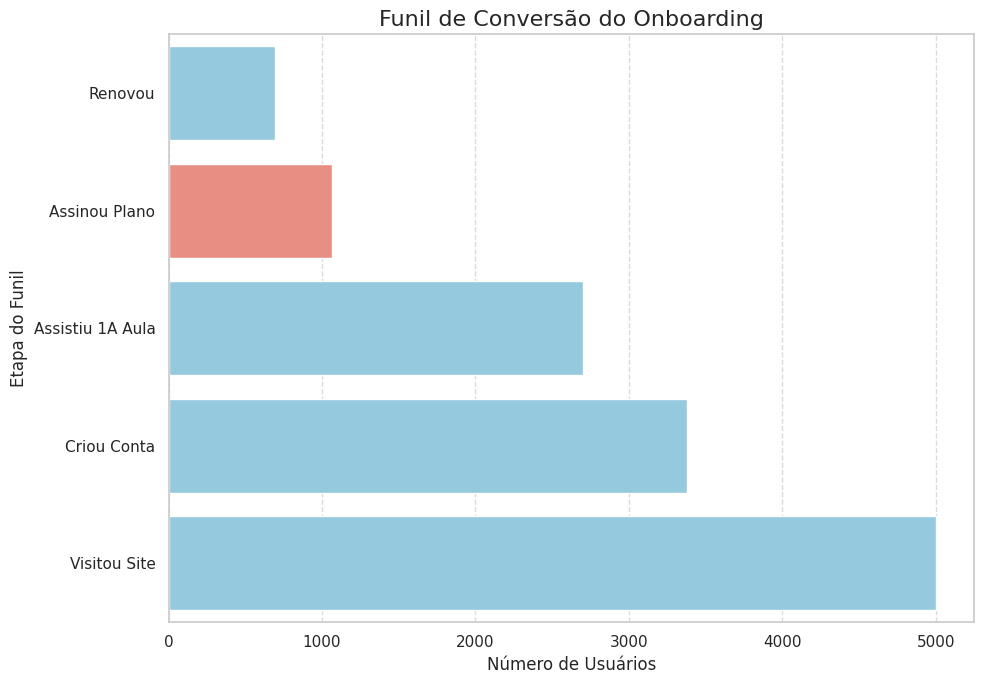

In [66]:
# 1. Padronizar a coluna 'etapa'
def padronizar_etapa(etapa):
    if pd.isna(etapa):
        return etapa
    return str(etapa).lower().replace(' ', '_').strip()

df_funil['etapa'] = df_funil['etapa'].apply(padronizar_etapa)
print("Valores únicos da coluna 'etapa' após padronização:")
display(df_funil['etapa'].unique())

# 2. Definir a ordem do funil
ordem_funil = [
    'visitou_site',
    'criou_conta',
    'assistiu_1a_aula',
    'assinou_plano',
    'renovou'
]

# Filtrar apenas as etapas do funil na ordem definida
df_funil_ordenado = df_funil[df_funil['etapa'].isin(ordem_funil)].copy()

# Contar clientes únicos por etapa
funil_counts = df_funil_ordenado.groupby('etapa')['cliente_id'].nunique().reindex(ordem_funil)

# 3. Montar a tabela do funil
tabela_funil = pd.DataFrame(funil_counts)
tabela_funil.columns = ['usuarios']

# Taxa de conversão da etapa anterior
tabela_funil['conversao_anterior'] = (tabela_funil['usuarios'] / tabela_funil['usuarios'].shift(1) * 100).fillna(100)

# Taxa de conversão em relação ao topo do funil
tabela_funil['conversao_topo'] = (tabela_funil['usuarios'] / tabela_funil['usuarios'].iloc[0] * 100).fillna(100)

print("\n=== Tabela de Funil de Conversão ===")
display(tabela_funil)

# 4. Identificar a etapa com a maior queda de conversão (maior gargalo)
# A maior queda é a menor taxa de conversao_anterior (excluindo a primeira etapa que é 100%)
maior_queda_idx = tabela_funil['conversao_anterior'][1:].idxmin()
maior_queda_valor = tabela_funil['conversao_anterior'][1:].min()

print(f"\nO maior gargalo do funil é na etapa '{maior_queda_idx}' com uma taxa de conversão de {maior_queda_valor:.2f}% da etapa anterior.")

# 5. Plotar o gráfico de Pareto

# Preparar dados para o gráfico (etapas e número de usuários)
plot_data = tabela_funil[['usuarios']].reset_index()
plot_data['etapa'] = plot_data['etapa'].str.replace('_', ' ').str.title()

# Definir cores para o gráfico, destacando o gargalo
colors = ['skyblue'] * len(plot_data)
if maior_queda_idx:
    gargalo_index = ordem_funil.index(maior_queda_idx)
    colors[gargalo_index] = 'salmon' # Cor para o gargalo

plt.figure(figsize=(10, 7))
sns.barplot(x='usuarios', y='etapa', data=plot_data.sort_values(by='usuarios', ascending=True),
            palette=colors[::-1], orient='h') # Inverter para exibir o funil corretamente

plt.title('Funil de Conversão do Onboarding', fontsize=16)
plt.xlabel('Número de Usuários', fontsize=12)
plt.ylabel('Etapa do Funil', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()